# Davíð's notebook

#### Exploratory analysis of the data

##### Load and inspect

We load the features, expert votes, train/test split, and feature descriptions, then check that every table covers the same 17,089 EEG segments. The votes and split groups are combined into one table (`meta`) for the analysis below.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_dir = "../HMSdata_prepared"
features = pd.read_csv(f"{data_dir}/features.csv")
labels = pd.read_csv(f"{data_dir}/label.csv")
split = pd.read_csv(f"{data_dir}/train_test.csv")
descriptions = pd.read_csv(f"{data_dir}/feature_descriptions.csv")

tables = {"features": features, "labels": labels, "split": split, "descriptions": descriptions}
for name, table in tables.items():
    print(name, table.shape)
    display(table.head(3))

features (17089, 96)


,segment_id,patient_id,eeg_logpow_delta1,eeg_logpow_delta2,eeg_logpow_theta,eeg_logpow_alpha,eeg_logpow_beta,eeg_relpow_delta1,eeg_relpow_delta2,eeg_relpow_theta,...,spect_reldelta_std,spect_reldelta_slope,spect_evo_peakfreq_range,spect_evo_logpow_range,spect_peakfreq_median,spect_entropy_median,spect_stability,spect_asym_delta,spect_asym_total,spect_nan_frac
0,1,42516,1.461893,1.540767,1.566393,1.018688,1.215860,0.207959,0.276346,0.228102,...,0.057239,0.002313,1.36,0.128195,2.15,0.816982,0.963119,0.217572,0.297412,0.0
1,2,30539,1.243672,1.309647,0.842975,0.277363,-0.449872,0.319113,0.468289,0.164293,...,0.039450,0.002434,2.15,0.108364,2.34,0.735160,0.751589,0.070416,0.064455,0.0
2,3,56885,2.570554,2.031281,1.343681,0.578681,0.168920,0.721561,0.214177,0.055476,...,0.035010,0.005553,0.39,0.525525,1.17,0.591299,0.982874,0.542108,0.532484,0.0


labels (17089, 10)


,segment_id,patient_id,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote,expert_consensus,num_votes
0,1,42516,3,0,0,0,0,0,Seizure,3
1,2,30539,0,0,5,0,1,5,GPD,11
2,3,56885,0,1,0,14,0,1,LRDA,16


split (17089, 4)


,segment_id,patient_id,num_votes,group
0,1,42516,3,excluded_low_votes
1,2,30539,11,train_pool
2,3,56885,16,train_pool


descriptions (94, 4)


,name,group,window,description
0,eeg_logpow_delta1,A1_spectral,c10,"log10 absolute power 0.5-2 Hz (µV²), median ov..."
1,eeg_logpow_delta2,A1_spectral,c10,"log10 absolute power 2-4 Hz (µV²), median over..."
2,eeg_logpow_theta,A1_spectral,c10,"log10 absolute power 4-8 Hz (µV²), median over..."


In [2]:
for name in ["features", "labels", "split"]:
    print(name, "unique ids:", tables[name]["segment_id"].is_unique)
print("same ids:", set(features["segment_id"]) == set(labels["segment_id"]) == set(split["segment_id"]))

# Take only the new column from split, so patient_id and num_votes aren't duplicated
meta = labels.merge(split[["segment_id", "group"]], on="segment_id", validate="one_to_one")
meta.shape

features unique ids: True
labels unique ids: True
split unique ids: True
same ids: True


(17089, 11)

##### Votes and classes

We look at how many experts labeled each segment, how often they agreed, and how common each class is in each split. This shows how much disagreement there is for active learning to work with, and whether train and test have similar class balance.

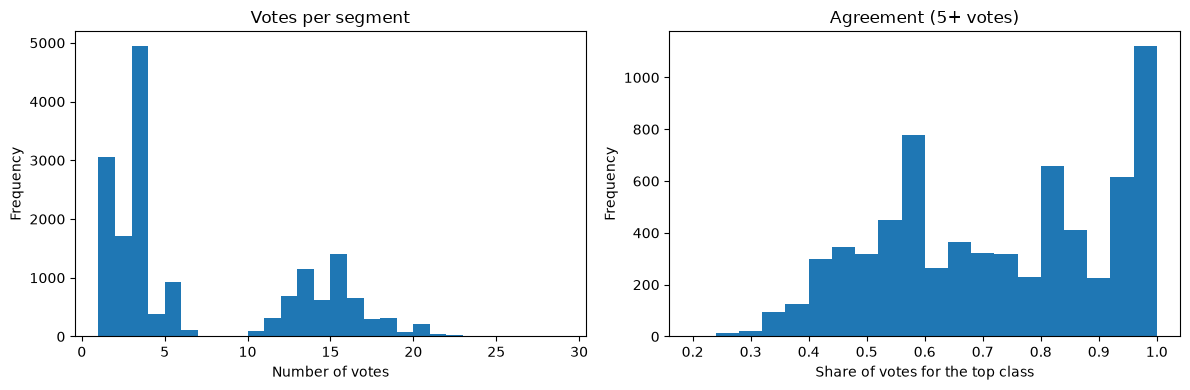

In [3]:
vote_cols = ["seizure_vote", "lpd_vote", "gpd_vote", "lrda_vote", "grda_vote", "other_vote"]
class_order = ["Seizure", "LPD", "GPD", "LRDA", "GRDA", "Other"]
group_order = ["train_pool", "excluded_low_votes", "test", "excluded_test_patient"]

soft_labels = meta[vote_cols].div(meta["num_votes"], axis=0)
meta["top_share"] = soft_labels.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
meta["num_votes"].plot.hist(bins=range(1, 30), ax=axes[0], title="Votes per segment")
axes[0].set_xlabel("Number of votes")
meta.loc[meta["num_votes"] >= 5, "top_share"].plot.hist(bins=20, ax=axes[1], title="Agreement (5+ votes)")
axes[1].set_xlabel("Share of votes for the top class")
plt.tight_layout()
plt.show()

group,train_pool,excluded_low_votes,test,excluded_test_patient
expert_consensus,,,,
Seizure,663,1362,48,555
LPD,1063,974,214,356
GPD,666,795,156,195
LRDA,265,495,61,125
GRDA,352,1038,88,366
Other,2560,3244,588,860


group,train_pool,excluded_low_votes,test,excluded_test_patient
expert_consensus,,,,
Seizure,0.119,0.172,0.042,0.226
LPD,0.191,0.123,0.185,0.145
GPD,0.120,0.101,0.135,0.079
LRDA,0.048,0.063,0.053,0.051
GRDA,0.063,0.131,0.076,0.149
Other,0.460,0.410,0.509,0.350


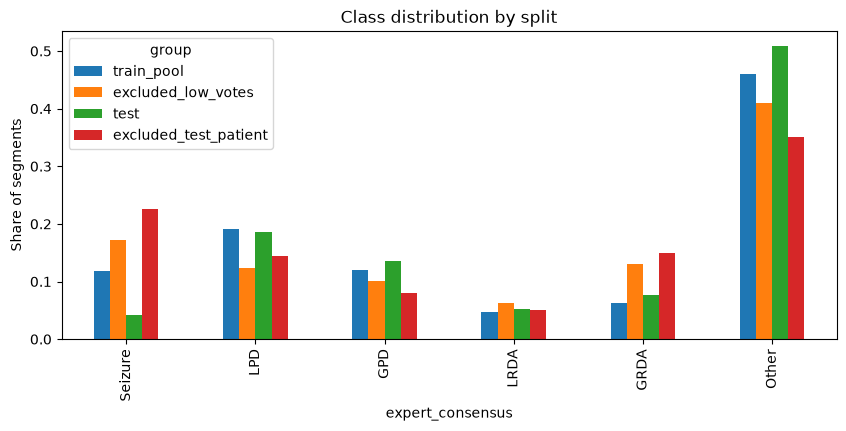

In [4]:
class_counts = pd.crosstab(meta["expert_consensus"], meta["group"]).loc[class_order, group_order]
class_shares = class_counts / class_counts.sum()
display(class_counts, class_shares.round(3))

class_shares.plot.bar(figsize=(10, 4), title="Class distribution by split", ylabel="Share of segments")
plt.show()

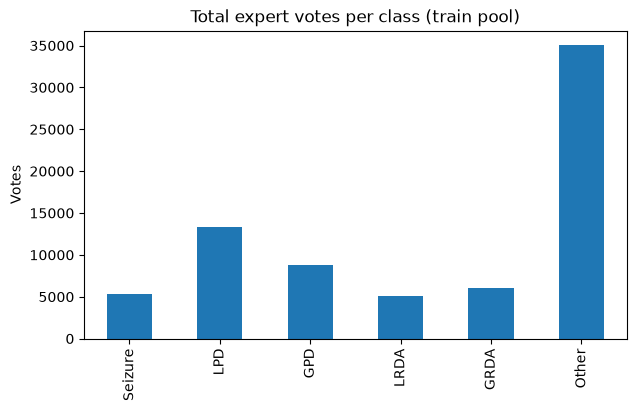

In [5]:
# Total expert votes per class in the training pool
total_votes = meta.loc[meta["group"] == "train_pool", vote_cols].sum()
total_votes.index = class_order

total_votes.plot.bar(figsize=(7, 4), title="Total expert votes per class (train pool)", ylabel="Votes")
plt.show()

#### Patients and splits

We summarize the segments, patients, and votes in each group and confirm that no patient appears in both train and test, which would inflate our results. We also check how unevenly segments are spread across patients.

,segments,patients,total_votes,median_votes
group,,,,
train_pool,5569,996,73587,14.0
excluded_low_votes,7908,1289,17558,3.0
test,1155,212,16952,15.0
excluded_test_patient,2457,352,6602,3.0


patients in both: 0


count    1950.0
mean        8.8
std        20.3
min         1.0
25%         2.0
50%         3.0
75%         5.0
max       270.0
dtype: float64

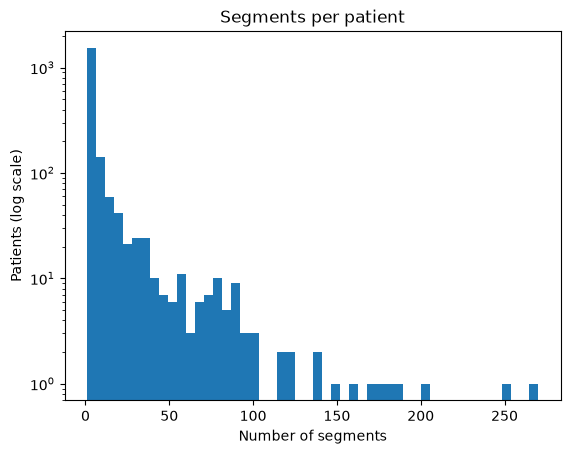

In [6]:
summary = (meta.groupby("group")
    .agg(segments=("segment_id", "size"), patients=("patient_id", "nunique"),
         total_votes=("num_votes", "sum"), median_votes=("num_votes", "median"))
    .loc[group_order])
display(summary)

test_patients = set(meta.loc[meta["group"].isin(["test", "excluded_test_patient"]), "patient_id"])
train_patients = set(meta.loc[meta["group"].isin(["train_pool", "excluded_low_votes"]), "patient_id"])
print("patients in both:", len(test_patients & train_patients))

segments_per_patient = meta.groupby("patient_id").size()
display(segments_per_patient.describe().round(1))
segments_per_patient.plot.hist(bins=50, log=True, title="Segments per patient")
plt.xlabel("Number of segments")
plt.ylabel("Patients (log scale)")
plt.show()

#### Features

We check how much data is missing per feature and how feature values differ between classes, using the training pool only. This guides the preprocessing and feature selection below.

features with missing values: 27 | highest: 0.144 %


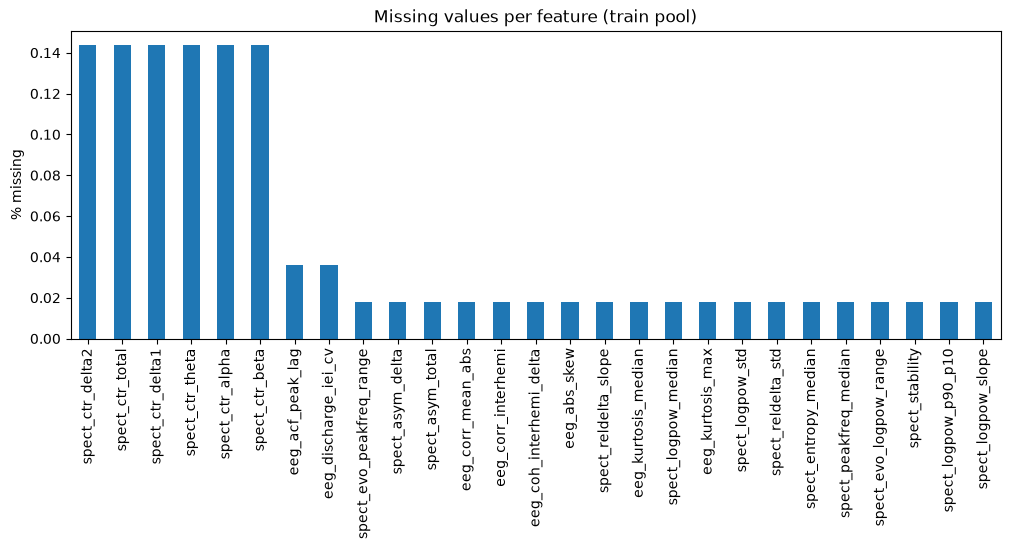

In [7]:
feature_cols = descriptions["name"].tolist()
train_features = features.merge(meta.loc[meta["group"] == "train_pool", ["segment_id", "expert_consensus"]],
                                on="segment_id", validate="one_to_one")

missing_pct = (train_features[feature_cols].isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print("features with missing values:", len(missing_pct), "| highest:", round(missing_pct.max(), 3), "%")

missing_pct.plot.bar(figsize=(12, 4), title="Missing values per feature (train pool)", ylabel="% missing")
plt.show()

##### Feature values by class

We plot one feature from each feature group, with a separate curve per class. Curves that separate clearly suggest the feature helps distinguish those classes.

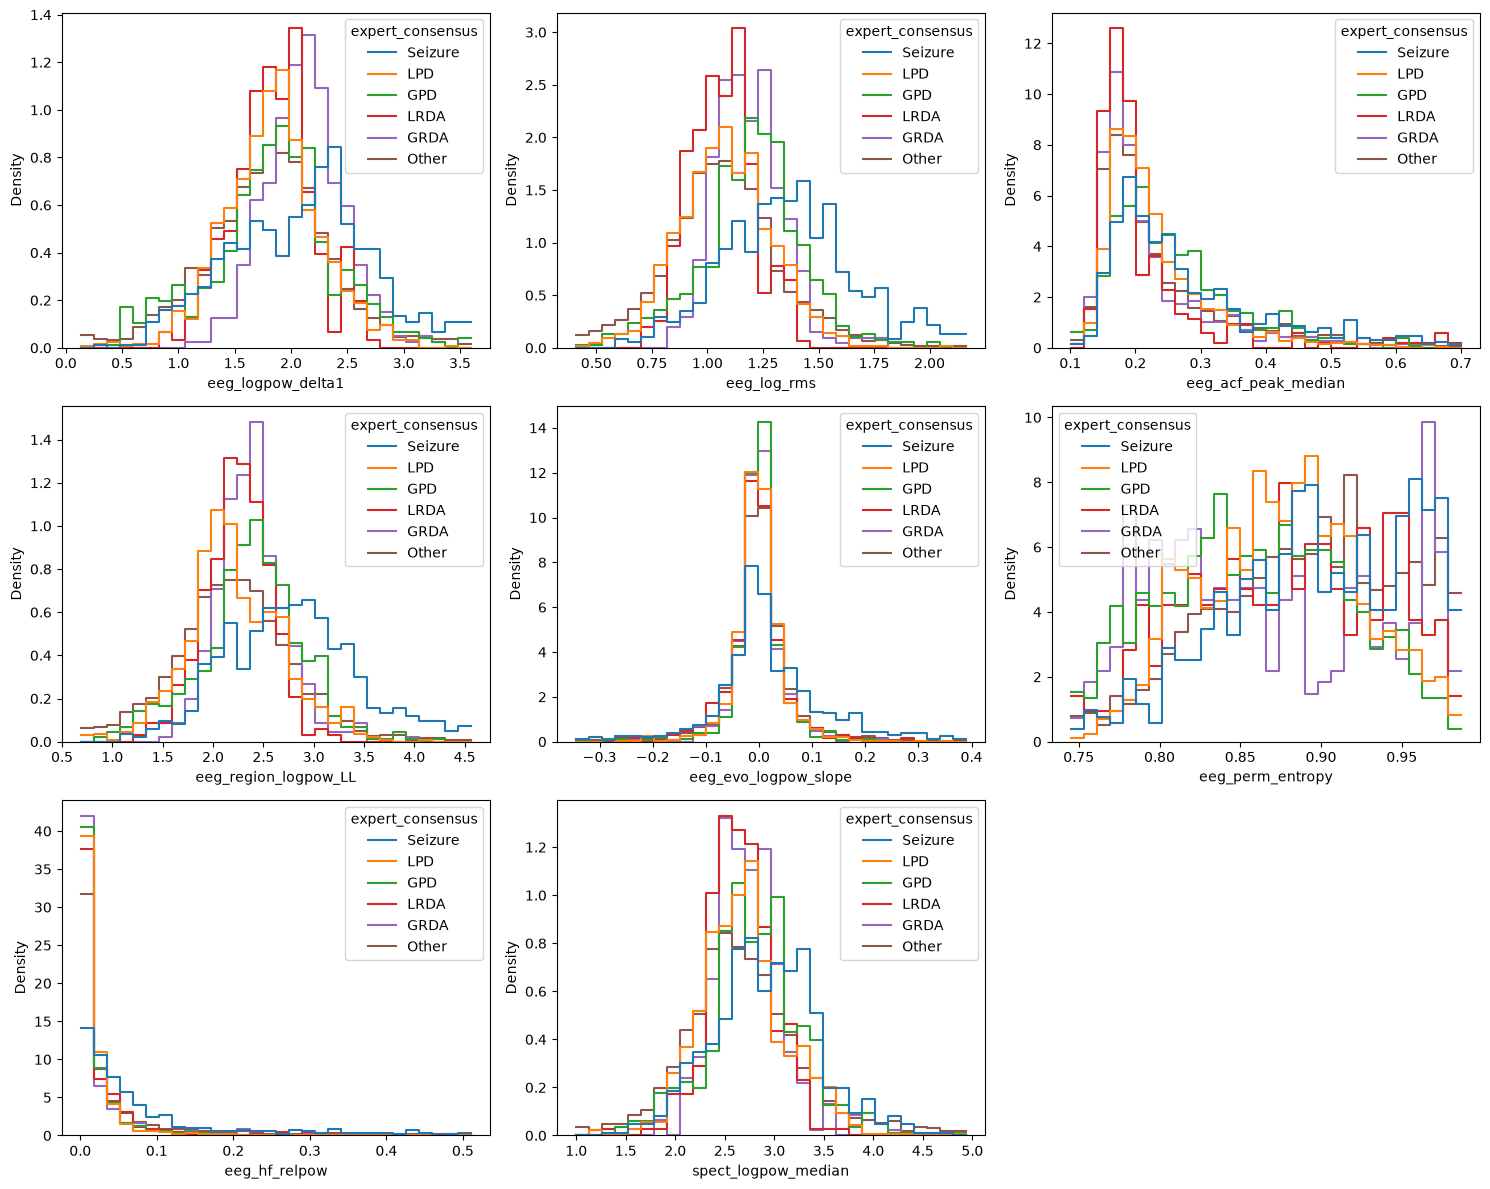

In [8]:
import numpy as np
import seaborn as sns

# One feature from each feature group, so every type of feature is represented
plot_features = descriptions.groupby("group")["name"].first().tolist()

n_cols = 3
n_rows = int(np.ceil(len(plot_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.ravel()

for ax, feature in zip(axes, plot_features):
    # Hide the most extreme 2% of values so the shapes are readable
    low, high = train_features[feature].quantile([0.01, 0.99])
    plot_data = train_features[train_features[feature].between(low, high)]

    # density + common_norm=False lets small classes be compared with large ones
    sns.histplot(data=plot_data, x=feature, hue="expert_consensus", hue_order=class_order,
                 stat="density", common_norm=False, element="step", fill=False, bins=30, ax=ax)

for ax in axes[len(plot_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

#### Split features into train and test

We separate the 94 features into the training pool and the test set using the split provided by Dr. Pale. All preprocessing below is learned from the training data only, so no test information leaks into the model.

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler

feature_cols = descriptions["name"].tolist()
data = features.merge(meta[["segment_id", "group"]], on="segment_id", validate="one_to_one")

train_data = data[data["group"] == "train_pool"]
test_data = data[data["group"] == "test"]

X_train = train_data[feature_cols]
X_test = test_data[feature_cols]
print(X_train.shape, X_test.shape)

(5569, 94) (1155, 94)


#### Impute missing values

A small number of feature values are missing, so we fill each one with that feature's median from the training set. The median is used because it is not distorted by extreme values.

In [10]:
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")

X_train_imp = imputer.fit_transform(X_train)   # learns medians from train
X_test_imp = imputer.transform(X_test)         # reuses the train medians

print("missing:", X_train_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())

missing: 0 0


#### Transform skewed features

Some features have a long tail of extreme values that can dominate a model. We apply a Yeo-Johnson transform, similar to a log transform but able to handle zeros and negative values, to features with |skew| > 2.

In [11]:
skewed_cols = X_train_imp.columns[X_train_imp.skew().abs() > 2].tolist()
power = PowerTransformer(method="yeo-johnson", standardize=False).set_output(transform="pandas")

X_train_pow = X_train_imp.copy()
X_test_pow = X_test_imp.copy()
X_train_pow[skewed_cols] = power.fit_transform(X_train_imp[skewed_cols])
X_test_pow[skewed_cols] = power.transform(X_test_imp[skewed_cols])

print("skewed before:", len(skewed_cols), "after:", (X_train_pow.skew().abs() > 2).sum())

skewed before: 39 after: 7


#### Standardize

We rescale every feature to mean 0 and standard deviation 1 using the training set's values. This puts features on a comparable scale, which matters especially for logistic regression.

In [12]:
scaler = StandardScaler().set_output(transform="pandas")

X_train_scaled = scaler.fit_transform(X_train_pow)
X_test_scaled = scaler.transform(X_test_pow)

X_train_scaled.describe().loc[["mean", "std"]].round(2)

,eeg_logpow_delta1,eeg_logpow_delta2,eeg_logpow_theta,eeg_logpow_alpha,eeg_logpow_beta,eeg_relpow_delta1,eeg_relpow_delta2,eeg_relpow_theta,eeg_relpow_alpha,eeg_relpow_beta,...,spect_reldelta_std,spect_reldelta_slope,spect_evo_peakfreq_range,spect_evo_logpow_range,spect_peakfreq_median,spect_entropy_median,spect_stability,spect_asym_delta,spect_asym_total,spect_nan_frac
mean,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,...,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### Drop near-constant features

Features with the same value in at least 95% of training segments carry almost no information, so we remove them. This takes us from 94 to 92 features.

In [13]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold

# Share of rows taken by each feature's most common value
top_share = X_train_scaled.apply(lambda col: col.value_counts(normalize=True).iloc[0])
near_constant = top_share[top_share >= 0.95].index.tolist()

candidates = [col for col in feature_cols if col not in near_constant]
print("dropped:", near_constant)
print("left:", len(candidates))

dropped: ['eeg_n_flat_channels', 'eeg_nan_frac']
left: 92


#### Drop highly correlated features

When two features are nearly identical (|r| > 0.95), we keep only one because the other adds little new information. This takes us from 92 to 84 features.

In [14]:
corr = X_train_scaled[candidates].corr().abs()

kept = []
for col in candidates:
    # Keep a feature only if it isn't too similar to one we already kept
    if (corr.loc[col, kept] <= 0.95).all():
        kept.append(col)

print("left:", len(kept))

left: 84


#### Rank by random forest importance

The earlier filters do not use the labels, so we train a random forest on the expert vote shares to rank features by how useful they are. Importance is averaged over 5 folds, keeping each patient within a single fold.

In [15]:
train_meta = meta.set_index("segment_id").loc[train_data["segment_id"]]
y_train = train_meta[vote_cols].div(train_meta["num_votes"], axis=0).to_numpy()
groups = train_data["patient_id"].to_numpy()

cv = GroupKFold(n_splits=5)
fold_importances = []

for train_idx, _ in cv.split(X_train_scaled[kept], y_train, groups):
    forest = RandomForestRegressor(n_estimators=200, max_features="sqrt",
                                   min_samples_leaf=5, n_jobs=-1, random_state=42)
    forest.fit(X_train_scaled[kept].iloc[train_idx], y_train[train_idx])
    fold_importances.append(forest.feature_importances_)

importance = pd.Series(np.mean(fold_importances, axis=0), index=kept).sort_values(ascending=False)
importance.head(10)

spect_asym_delta             0.044010
eeg_discharge_rate_median    0.039302
eeg_logpow_theta             0.030368
eeg_relpow_delta1            0.027267
eeg_logpow_alpha             0.027115
eeg_discharge_rate_max       0.025824
eeg_relpow_delta2            0.025526
eeg_logpow_delta2            0.022911
eeg_kurtosis_median          0.022861
eeg_asym_lat_theta           0.021808
dtype: float64

#### Keeping the best features

We compare different feature counts using cross-validated KL divergence on the training data, where lower is better. Performance levels off between 30 and 49 features, so we keep the top 30 as the smallest set on that plateau.

In [16]:
from scipy.special import rel_entr

def kl_divergence(y_true, y_pred, eps=1e-7):
    y_pred = np.clip(y_pred, eps, 1)                    # avoids log(0)
    y_pred = y_pred / y_pred.sum(axis=1, keepdims=True)  # sums to 1 again
    return rel_entr(y_true, y_pred).sum(axis=1).mean()

def make_forest():
    return RandomForestRegressor(n_estimators=200, max_features="sqrt",
                                 min_samples_leaf=5, n_jobs=-1, random_state=42)

feature_counts = [10, 20, 30, 40, 49, 60, 84]
X_kept = X_train_scaled[kept]
rows = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_kept, y_train, groups)):
    X_fit, X_val = X_kept.iloc[train_idx], X_kept.iloc[val_idx]
    y_fit, y_val = y_train[train_idx], y_train[val_idx]

    # Rank using this fold's training data only, so validation stays unseen
    ranking = pd.Series(make_forest().fit(X_fit, y_fit).feature_importances_,
                        index=kept).sort_values(ascending=False)

    for k in feature_counts:
        top_k = ranking.head(k).index
        model = make_forest().fit(X_fit[top_k], y_fit)
        kl = kl_divergence(y_val, model.predict(X_val[top_k]))
        rows.append({"fold": fold, "n_features": k, "kl": kl})

results = pd.DataFrame(rows)
summary = results.groupby("n_features")["kl"].agg(["mean", "std"])
summary["se"] = summary["std"] / np.sqrt(cv.get_n_splits())
summary.round(4)

,mean,std,se
n_features,,,
10,0.5606,0.0192,0.0086
20,0.5160,0.0240,0.0108
30,0.5093,0.0275,0.0123
40,0.5095,0.0261,0.0117
49,0.5099,0.0276,0.0123
60,0.5131,0.0265,0.0119
84,0.5160,0.0266,0.0119


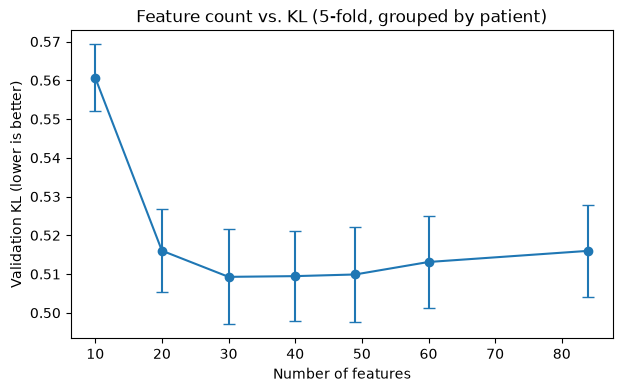

In [17]:
plt.figure(figsize=(7, 4))
plt.errorbar(summary.index, summary["mean"], yerr=summary["se"], marker="o", capsize=4)
plt.xlabel("Number of features")
plt.ylabel("Validation KL (lower is better)")
plt.title("Feature count vs. KL (5-fold, grouped by patient)")
plt.show()

In [18]:
n_features = 30
selected_features = importance.head(n_features).index.tolist()

X_train_final = X_train_scaled[selected_features]
X_test_final = X_test_scaled[selected_features]
print(X_train_final.shape, X_test_final.shape)

(5569, 30) (1155, 30)


### Model choice: logistic regression

#### Shared evaluation setup

The metrics (KL divergence and macro-F1) and cross-validation folds come from `src/evaluation.py`, so all three team models are compared on exactly the same terms.

In [19]:
import sys
sys.path.append("..")  # lets the notebook import the shared code in src/

from src.evaluation import (CLASS_NAMES, RANDOM_STATE, evaluate, get_cv_folds,
                            cross_validate, majority_class)
from src.preprocessing import load_selected_features

#### Prepare the data

The model inputs are the 30 selected, preprocessed features. The targets are soft labels, meaning each segment's share of expert votes per class, so the model learns how experts split rather than only the majority class.

In [20]:
# Soft labels for the test set (y_train and groups were created in the feature ranking step)
test_meta = meta.set_index("segment_id").loc[test_data["segment_id"]]
y_test = test_meta[vote_cols].div(test_meta["num_votes"], axis=0).to_numpy()

print("X:", X_train_final.shape, X_test_final.shape)
print("y:", y_train.shape, y_test.shape)
print("labels sum to 1:", np.allclose(y_train.sum(axis=1), 1), np.allclose(y_test.sum(axis=1), 1))
print("same features as the team file:", selected_features == load_selected_features())
print("rows line up with labels:", (train_meta.index == train_data["segment_id"]).all())

X: (5569, 30) (1155, 30)
y: (5569, 6) (1155, 6)
labels sum to 1: True True
same features as the team file: True
rows line up with labels: True


#### Cross-validation folds

All models are tuned on the same 5 folds of the training data, with each patient in only one fold and similar class balance in every fold. The test set is not used until the final evaluation.

In [21]:
folds = get_cv_folds(y_train, groups)

fold_sizes = pd.DataFrame(
    [np.bincount(majority_class(y_train[val_idx]), minlength=len(CLASS_NAMES)) for _, val_idx in folds],
    columns=CLASS_NAMES)
fold_sizes.index.name = "fold"
display(fold_sizes)

# Each patient must appear in only one validation fold
for train_idx, val_idx in folds:
    assert not set(groups[train_idx]) & set(groups[val_idx])
print("no patient in both train and validation of any fold")

,Seizure,LPD,GPD,LRDA,GRDA,Other
fold,,,,,,
0,132,212,133,53,70,512
1,133,212,133,53,70,512
2,133,212,133,53,70,512
3,132,213,133,53,70,511
4,133,214,134,53,72,513


no patient in both train and validation of any fold


#### Soft labels as weighted rows

Logistic regression accepts only one class per row, so each segment is repeated once per class that received votes, weighted by that class's share of the votes. This trains the model on the experts' full vote distribution, and the same shared function is used for all three team models. Expansion happens after splitting into folds, so a segment's rows never end up on both sides.

In [22]:
from src.models import expand_soft_labels

X_expanded, classes, weights = expand_soft_labels(X_train_final, y_train)
print("segments:", len(X_train_final), "-> rows:", len(X_expanded))

# Example: segment 2 had 11 votes (GPD 5, Other 5, GRDA 1), so it becomes 3 weighted rows
position = np.flatnonzero(train_data["segment_id"].to_numpy() == 2)[0]
segment_rows = np.flatnonzero(np.repeat(np.arange(len(y_train)), (y_train > 0).sum(axis=1)) == position)
display(pd.DataFrame({"class": np.array(CLASS_NAMES)[classes[segment_rows]],
                      "weight": weights[segment_rows].round(3)}))

# Each segment's weights add up to 1, so every segment counts equally
print("total weight:", round(weights.sum()), "= number of segments:", len(y_train))

segments: 5569 -> rows: 14015


,class,weight
0,GPD,0.455
1,GRDA,0.091
2,Other,0.455


total weight: 5569 = number of segments: 5569


#### Reference models

Before training logistic regression, we score two models that ignore the EEG features: one predicts equal shares for all classes, and one always predicts the average vote shares of the training folds. Any real model must clearly beat these, otherwise it has not learned anything from the features.

In [23]:
def fit_predict_prior(X_fit, y_fit, X_val):
    """Ignore the features and predict the training folds' average vote shares for every segment."""
    return np.tile(y_fit.mean(axis=0), (len(X_val), 1))

def fit_predict_uniform(X_fit, y_fit, X_val):
    """Predict an equal 1/6 share for every class."""
    return np.full((len(X_val), len(CLASS_NAMES)), 1 / len(CLASS_NAMES))

cv_results = {}  # collects every model's cross-validation scores for comparison
cv_results["uniform"] = cross_validate(fit_predict_uniform, X_train_final, y_train, folds)
cv_results["average shares"] = cross_validate(fit_predict_prior, X_train_final, y_train, folds)

def summarize(cv_results):
    """Mean and standard deviation across folds for each model."""
    return pd.DataFrame({name: {"kl_mean": r["kl"].mean(), "kl_std": r["kl"].std(),
                                "f1_mean": r["macro_f1"].mean(), "f1_std": r["macro_f1"].std()}
                         for name, r in cv_results.items()}).T.round(4)

summarize(cv_results)

,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001


#### Default logistic regression

We train multinomial logistic regression with default regularization (C = 1) on the weighted rows and score it on the shared folds. This is the starting point that tuning in the next steps must improve on.

In [24]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

def make_lr_fit_predict(**params):
    """Build a fit_predict function for logistic regression with the given settings."""
    def fit_predict(X_fit, y_fit, X_val):
        X_expanded, classes, weights = expand_soft_labels(X_fit, y_fit)  # expanded inside the fold
        model = LogisticRegression(max_iter=5000, **params)
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)  # stop if the solver doesn't converge
            model.fit(X_expanded, classes, sample_weight=weights)
        return model.predict_proba(X_val)
    return fit_predict

cv_results["LR default (C=1)"] = cross_validate(make_lr_fit_predict(C=1.0), X_train_final, y_train, folds)

display(cv_results["LR default (C=1)"].round(4))
summarize(cv_results)

,fold,kl,macro_f1
0,0,0.5751,0.4369
1,1,0.5030,0.5418
2,2,0.5321,0.5303
3,3,0.5316,0.4556
4,4,0.6233,0.4149


,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001
LR default (C=1),0.5530,0.0470,0.4759,0.0569


* **It clearly learns from the features:** KL drops by about 40% compared with the average-share reference.
* **Folds vary a lot:** KL ranges from 0.50 to 0.62 depending on the fold, so small differences when tuning won't mean much.
* **It underfits rather than overfits:** on fold 0, KL is 0.50 on its training data and 0.58 on validation. That's a small gap, so tuning C will probably help only a little.
* **Random forest may win the comparison:** it reached about 0.51 KL during feature selection, though on different folds. A linear model may simply be too simple here.

#### Tuning regularization strength (C)

C controls how strongly the model is kept simple: small C means strong regularization, large C means the model can fit the training data more closely. We try values from 0.001 to 100 on the shared folds and pick the one with the lowest KL, our main metric.

kl         macro_f1        
              mean     std     mean     std
C                                          
0.001000    0.6260  0.0362   0.3360  0.0219
0.003162    0.5756  0.0432   0.4094  0.0295
0.010000    0.5556  0.0468   0.4399  0.0454
0.031623    0.5507  0.0477   0.4578  0.0514
0.100000    0.5509  0.0475   0.4680  0.0543
0.316228    0.5521  0.0473   0.4748  0.0536
1.000000    0.5530  0.0470   0.4759  0.0569
3.162278    0.5535  0.0471   0.4754  0.0570
10.000000   0.5536  0.0470   0.4748  0.0558
31.622777   0.5538  0.0471   0.4747  0.0557
100.000000  0.5538  0.0471   0.4745  0.0553

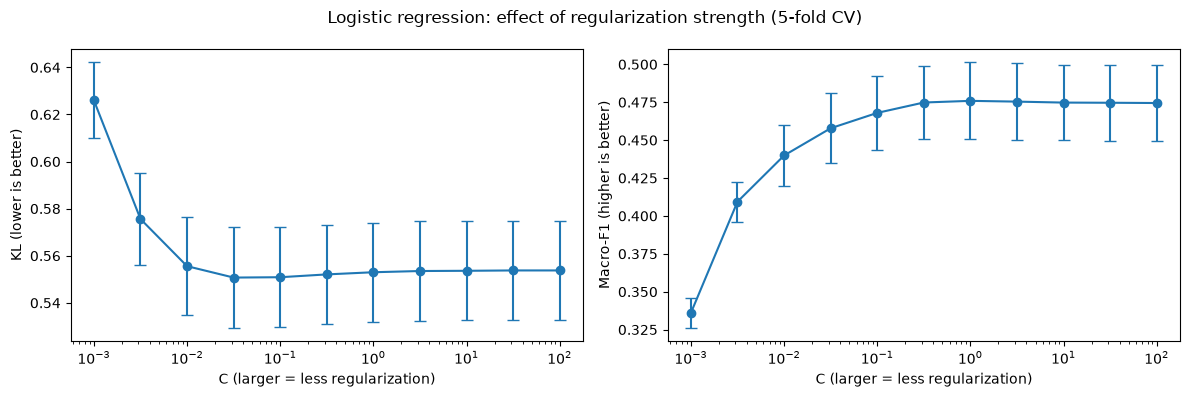

,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001
LR default (C=1),0.5530,0.0470,0.4759,0.0569
LR tuned (C=0.1),0.5509,0.0475,0.4680,0.0543


In [25]:
C_values = np.logspace(-3, 2, 11)  # 0.001 to 100, evenly spaced on a log scale

c_rows = []
for C in C_values:
    scores = cross_validate(make_lr_fit_predict(C=C), X_train_final, y_train, folds)
    scores["C"] = C
    c_rows.append(scores)
c_search = pd.concat(c_rows)

c_summary = c_search.groupby("C")[["kl", "macro_f1"]].agg(["mean", "std"])
display(c_summary.round(4))

# Plot both metrics against C, with error bars of one standard error across folds
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, label in zip(axes, ["kl", "macro_f1"], ["KL (lower is better)", "Macro-F1 (higher is better)"]):
    se = c_summary[(metric, "std")] / np.sqrt(len(folds))
    ax.errorbar(c_summary.index, c_summary[(metric, "mean")], yerr=se, marker="o", capsize=4)
    ax.set_xscale("log")
    ax.set_xlabel("C (larger = less regularization)")
    ax.set_ylabel(label)
fig.suptitle("Logistic regression: effect of regularization strength (5-fold CV)")
plt.tight_layout()
plt.show()

# KL is flat from C = 0.03 upward; 0.1 is essentially tied for the best KL and loses little macro-F1
best_C = 0.1
cv_results[f"LR tuned (C={best_C})"] = cross_validate(make_lr_fit_predict(C=best_C), X_train_final, y_train, folds)
summarize(cv_results)

#### Refinements

Starting from C = 0.1, we test one change at a time and keep it only if cross-validated KL improves consistently across folds:
- **Balanced class weights:** give rare classes more weight, which can help macro-F1.
- **L1 penalty:** pushes unhelpful feature weights to exactly zero.
- **Capping feature values:** limits each standardized feature to ±threshold, so extreme values cannot dominate a linear model.

In [26]:
def make_clipped_lr(threshold, **params):
    """Logistic regression on features capped at ±threshold standard deviations."""
    fit_predict = make_lr_fit_predict(**params)
    return lambda X_fit, y_fit, X_val: fit_predict(X_fit.clip(-threshold, threshold), y_fit,
                                                   X_val.clip(-threshold, threshold))

refinements = {
    "balanced class weights": make_lr_fit_predict(C=best_C, class_weight="balanced"),
    "L1 penalty": make_lr_fit_predict(C=best_C, solver="saga", l1_ratio=1.0),
}
for threshold in [5, 3, 2, 1.5, 1.25, 1, 0.75]:
    refinements[f"clip ±{threshold}"] = make_clipped_lr(threshold, C=best_C)

baseline = cv_results[f"LR tuned (C={best_C})"]
refinement_rows = []
for name, fit_predict in refinements.items():
    scores = cross_validate(fit_predict, X_train_final, y_train, folds)
    refinement_rows.append({
        "refinement": name,
        "kl": scores["kl"].mean(),
        "macro_f1": scores["macro_f1"].mean(),
        "kl_change": (scores["kl"] - baseline["kl"]).mean(),            # negative = better
        "folds_improved": int((scores["kl"] < baseline["kl"]).sum()),   # out of 5
    })
pd.DataFrame(refinement_rows).set_index("refinement").round(4)

,kl,macro_f1,kl_change,folds_improved
refinement,,,,
balanced class weights,0.7644,0.4743,0.2135,0
L1 penalty,0.5535,0.4536,0.0026,1
clip ±5,0.5448,0.4685,-0.0061,5
clip ±3,0.5358,0.4721,-0.0151,5
clip ±2,0.5252,0.4819,-0.0257,5
clip ±1.5,0.5186,0.4882,-0.0323,5
clip ±1.25,0.5177,0.4857,-0.0332,5
clip ±1,0.5191,0.4861,-0.0318,5
clip ±0.75,0.5253,0.4715,-0.0256,5


Class weighting makes KL much worse, because it pushes predicted shares away from how experts actually vote, and L1 gives no gain. Capping features helps in every fold, and keeps helping well below the usual outlier range: the best results come from capping at ±1.25 to ±1.5 standard deviations. This works less as outlier removal and more as a simple nonlinearity, since the model can no longer extrapolate linearly for extreme values. We keep C = 0.1 with features capped at ±1.5.

In [27]:
clip_threshold = 1.5  # best KL/macro-F1 trade-off in the comparison above
lr_final_name = f"LR final (C={best_C}, clip ±{clip_threshold})"
cv_results[lr_final_name] = cross_validate(make_clipped_lr(clip_threshold, C=best_C),
                                           X_train_final, y_train, folds)
summarize(cv_results)

,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001
LR default (C=1),0.5530,0.0470,0.4759,0.0569
LR tuned (C=0.1),0.5509,0.0475,0.4680,0.0543
"LR final (C=0.1, clip ±1.5)",0.5186,0.0402,0.4882,0.0625


#### Final evaluation on the test set

We train the final model (C = 0.1, features capped at ±1.5) on the full training pool and evaluate it once on the held-out test patients. The test set was not used for any earlier decision, so these are our unbiased results. The per-class scores and confusion matrix show which EEG patterns the model confuses.

,kl,macro_f1,cv_kl
average shares (reference),0.8768,0.1124,0.9358
"LR final (C=0.1, clip ±1.5)",0.5217,0.4467,0.5186


              precision    recall  f1-score   support

     Seizure      0.375     0.438     0.404        48
         LPD      0.630     0.509     0.563       214
         GPD      0.652     0.564     0.605       156
        LRDA      0.333     0.033     0.060        61
        GRDA      0.526     0.227     0.317        88
       Other      0.653     0.830     0.731       588

    accuracy                          0.630      1155
   macro avg      0.528     0.433     0.447      1155
weighted avg      0.611     0.630     0.602      1155



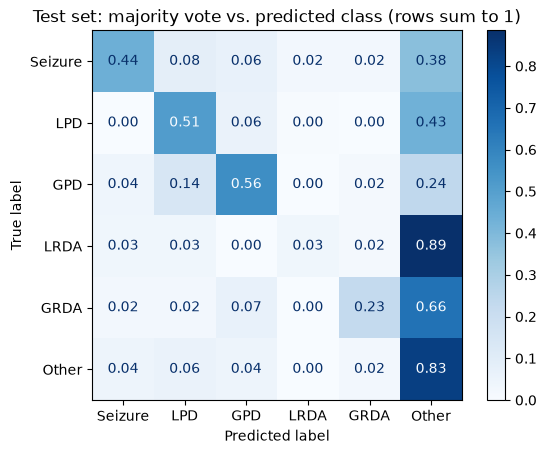

In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Train the final model once on all training data, then predict the test set
final_lr = make_clipped_lr(clip_threshold, C=best_C)
test_pred = final_lr(X_train_final, y_train, X_test_final)
reference_pred = fit_predict_prior(X_train_final, y_train, X_test_final)

test_results = pd.DataFrame({
    "average shares (reference)": evaluate(y_test, reference_pred),
    lr_final_name: evaluate(y_test, test_pred),
}).T.astype(float)
test_results["cv_kl"] = [cv_results["average shares"]["kl"].mean(), cv_results[lr_final_name]["kl"].mean()]
display(test_results.round(4))

# Per-class results: which patterns the model finds easy or hard
true_class, pred_class = majority_class(y_test), majority_class(test_pred)
print(classification_report(true_class, pred_class, labels=range(len(CLASS_NAMES)),
                            target_names=CLASS_NAMES, digits=3, zero_division=0))

ConfusionMatrixDisplay.from_predictions(true_class, pred_class, labels=range(len(CLASS_NAMES)),
                                        display_labels=CLASS_NAMES, normalize="true",
                                        values_format=".2f", cmap="Blues")
plt.title("Test set: majority vote vs. predicted class (rows sum to 1)")
plt.show()

### Further optimization: spline features

Capping helped because it gave the model a simple nonlinearity. Splines do this more flexibly: each feature is turned into a set of smooth curve pieces, so the model can learn a curved relationship between each feature and each class while still using the same 30 inputs. We tune the number of knots (how flexible each curve is) together with C, on the shared folds only, and compare against the current model (C = 0.1, capped at ±1.5). This takes about a minute to run.

In [29]:
from sklearn.preprocessing import SplineTransformer

def make_spline_lr(n_knots, **params):
    """Logistic regression on spline features: each feature becomes a smooth, flexible curve."""
    fit_predict = make_lr_fit_predict(**params)
    def spline_fit_predict(X_fit, y_fit, X_val):
        # Fitted inside each fold. Knots sit at quantiles of the training data, and values
        # beyond the training range are held constant (similar to capping).
        spline = SplineTransformer(n_knots=n_knots, degree=3, knots="quantile", extrapolation="constant")
        return fit_predict(spline.fit_transform(X_fit), y_fit, spline.transform(X_val))
    return spline_fit_predict

knot_values = [3, 5, 7, 9]
spline_C_values = [0.03, 0.1, 0.3, 1, 3, 10]
current_best = cv_results[lr_final_name]  # C = 0.1, capped at ±1.5

spline_rows = []
for n_knots in knot_values:
    for C in spline_C_values:
        scores = cross_validate(make_spline_lr(n_knots, C=C), X_train_final, y_train, folds)
        spline_rows.append({
            "n_knots": n_knots, "C": C,
            "kl": scores["kl"].mean(),
            "macro_f1": scores["macro_f1"].mean(),
            "kl_change": (scores["kl"] - current_best["kl"]).mean(),            # negative = better
            "folds_improved": int((scores["kl"] < current_best["kl"]).sum()),   # out of 5
        })
spline_search = pd.DataFrame(spline_rows)

# Mean KL for every combination (rows: knots, columns: C)
display(spline_search.pivot(index="n_knots", columns="C", values="kl").round(4))

best_spline = spline_search.loc[spline_search["kl"].idxmin()]
display(best_spline.to_frame("best by KL").T.round(4))

C,0.03,0.10,0.30,1.00,3.00,10.00
n_knots,,,,,,
3,0.5526,0.4984,0.4763,0.4653,0.4583,0.4526
5,0.4914,0.4601,0.4483,0.4448,0.4455,0.4473
7,0.4794,0.4543,0.4471,0.4472,0.4510,0.4555
9,0.4807,0.4568,0.4514,0.4542,0.4598,0.4661


,n_knots,C,kl,macro_f1,kl_change,folds_improved
best by KL,5.0,1.0,0.4448,0.5428,-0.0738,5.0


#### Calibration check

Active learning strategies such as entropy and least-confidence sampling read the model's predicted probabilities directly, so those probabilities should match how experts actually vote. We check this on out-of-fold predictions: if the model predicts 30% LPD for a group of segments, about 30% of the votes on them should be LPD. Points on the diagonal mean good calibration. We also test temperature scaling, a single number that softens or sharpens all predictions, and keep it only if it improves KL.

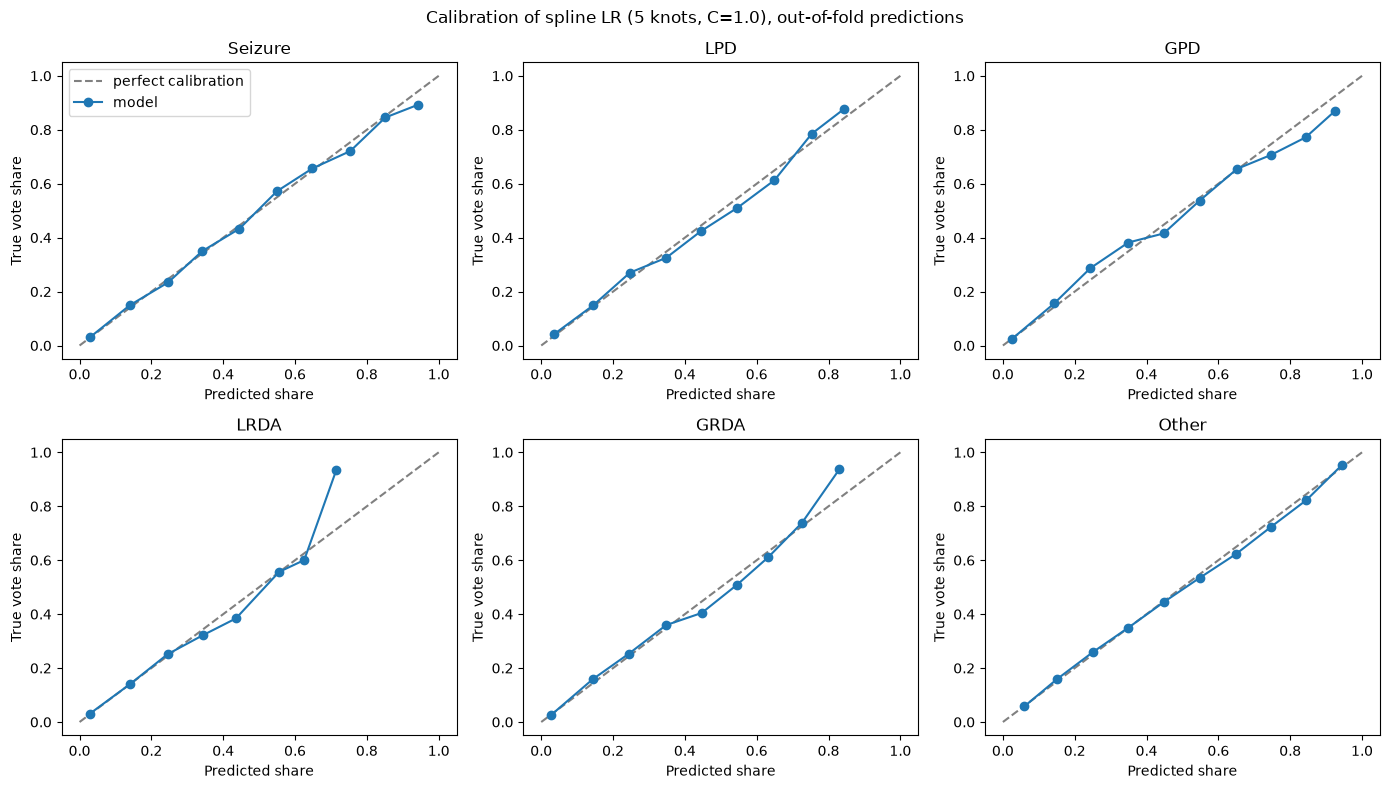

,calibration_error,mean_predicted,mean_true
class,,,
Seizure,0.0045,0.1067,0.1075
LPD,0.0122,0.1790,0.1814
GPD,0.0081,0.1201,0.1212
LRDA,0.0032,0.0686,0.0697
GRDA,0.0051,0.0805,0.0810
Other,0.0109,0.4451,0.4392


,temperature,kl_before,kl_after
fold,,,
0,1.0221,0.4367,0.4357
1,1.0388,0.4154,0.4157
2,1.0418,0.4410,0.4418
3,1.0424,0.4308,0.4317
4,1.0179,0.5002,0.4991


mean KL before: 0.4448 | after: 0.4448


In [30]:
from scipy.optimize import minimize_scalar

spline_knots, spline_C = int(best_spline["n_knots"]), float(best_spline["C"])
spline_lr = make_spline_lr(spline_knots, C=spline_C)

# Out-of-fold predictions: every training segment is predicted by a model that never saw it
oof_pred = np.zeros_like(y_train)
fold_of = np.zeros(len(y_train), dtype=int)
for fold, (train_idx, val_idx) in enumerate(folds):
    oof_pred[val_idx] = spline_lr(X_train_final.iloc[train_idx], y_train[train_idx], X_train_final.iloc[val_idx])
    fold_of[val_idx] = fold

# Reliability plots: average predicted share vs. average true vote share, in 10 bins per class
bins = np.linspace(0, 1, 11)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
calibration_rows = []
for k, (ax, name) in enumerate(zip(axes.ravel(), CLASS_NAMES)):
    bin_of = np.clip(np.digitize(oof_pred[:, k], bins) - 1, 0, 9)
    per_bin = (pd.DataFrame({"bin": bin_of, "pred": oof_pred[:, k], "true": y_train[:, k]})
               .groupby("bin").agg(pred=("pred", "mean"), true=("true", "mean"), n=("pred", "size")))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.plot(per_bin["pred"], per_bin["true"], marker="o", label="model")
    ax.set_title(name)
    ax.set_xlabel("Predicted share")
    ax.set_ylabel("True vote share")
    # Expected calibration error: average gap from the diagonal, weighted by segments per bin
    calibration_rows.append({"class": name,
                             "calibration_error": (per_bin["n"] * (per_bin["pred"] - per_bin["true"]).abs()).sum() / len(y_train),
                             "mean_predicted": oof_pred[:, k].mean(), "mean_true": y_train[:, k].mean()})
axes[0, 0].legend()
fig.suptitle(f"Calibration of spline LR ({spline_knots} knots, C={spline_C}), out-of-fold predictions")
plt.tight_layout()
plt.show()
display(pd.DataFrame(calibration_rows).set_index("class").round(4))

# Temperature scaling: T > 1 softens overconfident predictions, T < 1 sharpens underconfident ones.
# T is fitted on four folds' predictions and applied to the fifth, so each fold is scored fairly.
def apply_temperature(pred, T):
    scaled = np.clip(pred, 1e-12, 1) ** (1 / T)
    return scaled / scaled.sum(axis=1, keepdims=True)

def fit_temperature(pred, y_true):
    result = minimize_scalar(lambda log_T: evaluate(y_true, apply_temperature(pred, np.exp(log_T)))["kl"],
                             bounds=(np.log(0.25), np.log(4)), method="bounded")
    return np.exp(result.x)

temperature_rows = []
for fold in range(len(folds)):
    held_out = fold_of == fold
    T = fit_temperature(oof_pred[~held_out], y_train[~held_out])
    temperature_rows.append({
        "fold": fold, "temperature": T,
        "kl_before": evaluate(y_train[held_out], oof_pred[held_out])["kl"],
        "kl_after": evaluate(y_train[held_out], apply_temperature(oof_pred[held_out], T))["kl"],
    })
temperature_results = pd.DataFrame(temperature_rows).set_index("fold")
display(temperature_results.round(4))
print("mean KL before:", round(temperature_results["kl_before"].mean(), 4),
      "| after:", round(temperature_results["kl_after"].mean(), 4))

#### Test evaluation of the spline model

The spline model (5 knots, C = 1) was chosen using cross-validation only. We now train it on the full training pool and evaluate it once on the held-out test patients, next to the earlier capped model, to see whether the cross-validation gain holds on unseen patients.

,kl,macro_f1,cv_kl,cv_macro_f1
average shares (reference),0.8768,0.1124,0.9358,0.1050
"LR final (C=0.1, clip ±1.5)",0.5217,0.4467,0.5186,0.4882
"LR spline (5 knots, C=1.0)",0.4667,0.5062,0.4448,0.5428


              precision    recall  f1-score   support

     Seizure      0.375     0.500     0.429        48
         LPD      0.633     0.654     0.644       214
         GPD      0.695     0.526     0.599       156
        LRDA      0.364     0.131     0.193        61
        GRDA      0.658     0.284     0.397        88
       Other      0.718     0.845     0.777       588

    accuracy                          0.672      1155
   macro avg      0.574     0.490     0.506      1155
weighted avg      0.662     0.672     0.654      1155



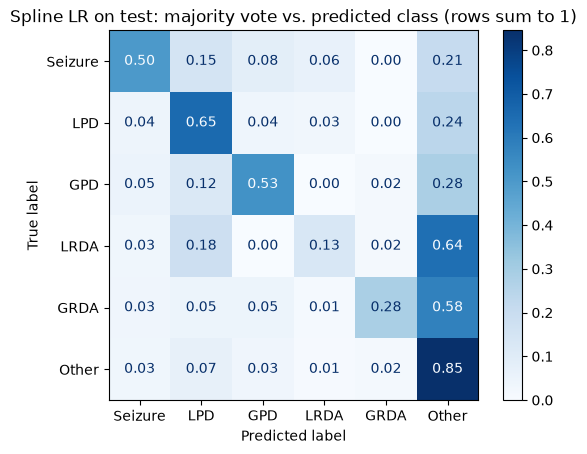

In [31]:
spline_name = f"LR spline ({spline_knots} knots, C={spline_C})"
cv_results[spline_name] = cross_validate(spline_lr, X_train_final, y_train, folds)

# Train once on the full training pool, then predict the held-out test patients
spline_test_pred = spline_lr(X_train_final, y_train, X_test_final)
capped_test_pred = make_clipped_lr(clip_threshold, C=best_C)(X_train_final, y_train, X_test_final)

final_comparison = pd.DataFrame({
    "average shares (reference)": evaluate(y_test, reference_pred),
    lr_final_name: evaluate(y_test, capped_test_pred),
    spline_name: evaluate(y_test, spline_test_pred),
}).T.astype(float)
final_comparison["cv_kl"] = [cv_results[name]["kl"].mean()
                             for name in ["average shares", lr_final_name, spline_name]]
final_comparison["cv_macro_f1"] = [cv_results[name]["macro_f1"].mean()
                                   for name in ["average shares", lr_final_name, spline_name]]
display(final_comparison.round(4))

# Per-class results for the spline model
spline_pred_class = majority_class(spline_test_pred)
print(classification_report(true_class, spline_pred_class, labels=range(len(CLASS_NAMES)),
                            target_names=CLASS_NAMES, digits=3, zero_division=0))

ConfusionMatrixDisplay.from_predictions(true_class, spline_pred_class, labels=range(len(CLASS_NAMES)),
                                        display_labels=CLASS_NAMES, normalize="true",
                                        values_format=".2f", cmap="Blues")
plt.title("Spline LR on test: majority vote vs. predicted class (rows sum to 1)")
plt.show()

### Notes and limitations for active learning

- **Feature selection used all training labels.** The 30 features were chosen with random forest importance computed on the vote shares of the entire training pool. In the active learning simulation those labels are supposed to be unknown at the start, so every strategy begins with a feature set that already reflects the full labels. This affects all strategies equally, so comparisons between them stay fair, but absolute performance in early rounds is somewhat optimistic. A stricter alternative is to reselect features using only the initial labeled set.
- **Spline knots can be fitted once on the whole training pool.** Knots are placed at quantiles of the feature values and use no labels. In active learning the unlabeled pool's features are known from the start, so this is not leakage. It also keeps the model's inputs stable across rounds, so changes in performance come from new labels rather than shifting knots. It matches how imputation, the skew transform and scaling are already fitted on the whole training pool. Test features must never be included.
- **Calibration was checked on the full training pool only.** Early rounds train on far fewer segments, where predictions may be less well calibrated, so calibration should be rechecked inside the loop.